# Đồ thị 09 Số hồ sơ theo nhãn DEATH_EVENT

**Võ Minh Huy — 2311110117**

Đây là đồ thị từ dữ liệu tổng hợp: đếm số hồ sơ theo nhãn 0, nhãn 1 và nhãn chờ xác minh. Dùng đủ 299 hồ sơ, không điền nhãn thiếu. Tỷ lệ của cả ba nhóm cùng có mẫu số 299.

Nhãn 0: không ghi nhận tử vong trong thời gian theo dõi; nhãn 1: ghi nhận tử vong. Nhãn chờ xác minh biểu diễn một hồ sơ có mã gốc không hợp lệ đã chuyển thành thiếu. Không gọi nhãn 0 là không có bệnh.


In [1]:
from pathlib import Path
import sys
import subprocess
import numpy as np
import pandas as pd
try:
    import matplotlib.pyplot as plt
except ModuleNotFoundError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "matplotlib"])
    import matplotlib.pyplot as plt

thu_muc = Path.cwd()
if thu_muc.name == "python":
    thu_muc = thu_muc.parent
du_lieu = pd.read_csv(thu_muc / "VoMinhHuy_Heart Failure Prediction_after_Python.csv")
nhan = pd.to_numeric(du_lieu["DEATH_EVENT"],errors="raise")
if len(du_lieu) != 299 or (nhan.notna() & ~nhan.isin([0,1])).any():
    raise ValueError("Cần 299 hồ sơ, nhãn chỉ có 0/1 hoặc thiếu chờ xác minh.")
thu_muc_kq = thu_muc / "ket_qua/21_do_thi/09_bar_nhan"
thu_muc_kq.mkdir(parents=True,exist_ok=True)
so_luong = [int(nhan.eq(0).sum()),int(nhan.eq(1).sum()),int(nhan.isna().sum())]
assert so_luong == [203,95,1] and sum(so_luong) == len(du_lieu)
bang_tong_hop = pd.DataFrame({"NhomNhan":["0","1","Chờ xác minh"],
    "MoTa":["Không ghi nhận tử vong","Ghi nhận tử vong","Nhãn thiếu chờ xác minh"],
    "SoHoSo":so_luong,"MauSo":[len(du_lieu)]*3})
bang_tong_hop["TyLePhanTram"] = 100*bang_tong_hop["SoHoSo"]/bang_tong_hop["MauSo"]
bang_tong_hop.round(2)


,NhomNhan,MoTa,SoHoSo,MauSo,TyLePhanTram
0,0,Không ghi nhận tử vong,203,299,67.89
1,1,Ghi nhận tử vong,95,299,31.77
2,Chờ xác minh,Nhãn thiếu chờ xác minh,1,299,0.33


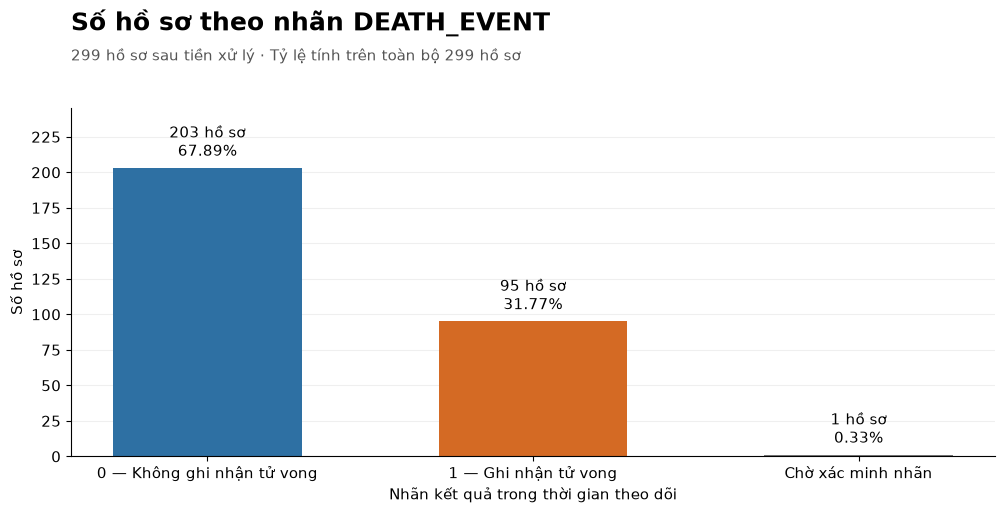

In [2]:
plt.rcParams.update({"font.family":"DejaVu Sans","font.size":11})
fig, ax = plt.subplots(figsize=(10.5,6))
fig.subplots_adjust(top=0.81,bottom=0.23,left=0.10,right=0.98)
fig.text(0.10,0.94,"Số hồ sơ theo nhãn DEATH_EVENT",fontsize=18,weight="bold")
fig.text(0.10,0.89,"299 hồ sơ sau tiền xử lý · Tỷ lệ tính trên toàn bộ 299 hồ sơ",color="#555555")
vi_tri = np.arange(3)
cot_ve = ax.bar(vi_tri,bang_tong_hop["SoHoSo"],width=0.58,
    color=["#2E70A3","#D46A24","#777777"])
assert [int(c.get_height()) for c in cot_ve] == so_luong
for c, ty_le in zip(cot_ve,bang_tong_hop["TyLePhanTram"]):
    ax.text(c.get_x()+c.get_width()/2,c.get_height()+5,
        f"{int(c.get_height())} hồ sơ\n{ty_le:.2f}%",ha="center",va="bottom",fontsize=11)
ax.set_xticks(vi_tri,labels=["0 — Không ghi nhận tử vong","1 — Ghi nhận tử vong","Chờ xác minh nhãn"])
ax.set(xlabel="Nhãn kết quả trong thời gian theo dõi",ylabel="Số hồ sơ",ylim=(0,245))
ax.set_yticks(np.arange(0,226,25))
ax.grid(axis="y",alpha=0.2)
ax.set_axisbelow(True)
ax.spines[["top","right"]].set_visible(False)
fig.savefig(thu_muc_kq / "09_bar_nhan.png",dpi=300,bbox_inches="tight",facecolor="white")
bang_tong_hop.to_csv(thu_muc_kq / "tong_hop_python.csv",index=False,encoding="utf-8-sig")
plt.show()


## Nhận xét

Có 203 hồ sơ nhãn 0 (67,89%), 95 hồ sơ nhãn 1 (31,77%) và 1 hồ sơ chờ xác minh (0,33%). Ba nhóm cộng lại đủ 299 hồ sơ. Tổng tỷ lệ hiển thị có thể là 99,99% do làm tròn từng nhóm đến hai chữ số.

Nhóm 0 nhiều hơn nhóm 1 trong tập hồ sơ này. Không dùng tỷ lệ trên để suy ra nguy cơ tử vong trong dân số hoặc kết quả dự đoán. Các phân tích cần nhãn hợp lệ dùng 298 hồ sơ; đồ thị mô tả tổng thể này giữ riêng nhóm chờ xác minh, không tự gán nhãn cho hồ sơ đó. File after giữ nguyên.
